In [1]:
import zipfile
import os

zip_path = '/content/archive (2).zip'
extract_path = '/content/extracted_data'

os.makedirs(extract_path, exist_ok=True)
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(f"Extracted all files to: {extract_path}")
print(os.listdir(extract_path))

Extracted all files to: /content/extracted_data
['sales_data.csv']


In [2]:
import pandas as pd
df =pd.read_csv('/content/extracted_data/sales_data.csv')

In [ ]:
df.describe()

,Inventory Level,Units Sold,Units Ordered,Price,Discount,Promotion,Competitor Pricing,Epidemic,Demand
count,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000
mean,301.062842,88.827316,89.090645,67.726028,9.087039,0.328947,69.454029,0.200000,104.317158
std,226.510161,43.994525,162.404627,39.377899,7.475781,0.469834,40.943818,0.400003,46.964801
min,0.000000,0.000000,0.000000,4.740000,0.000000,0.000000,4.290000,0.000000,4.000000
25%,136.000000,58.000000,0.000000,31.997500,5.000000,0.000000,32.620000,0.000000,71.000000
50%,227.000000,84.000000,0.000000,64.500000,10.000000,0.000000,65.700000,0.000000,100.000000
75%,408.000000,114.000000,121.000000,95.830000,10.000000,1.000000,97.932500,0.000000,133.000000
max,2267.000000,426.000000,1616.000000,228.030000,25.000000,1.000000,261.220000,1.000000,430.000000


In [ ]:
df.dtypes

,0
Date,object
Store ID,object
Product ID,object
Category,object
Region,object
Inventory Level,int64
Units Sold,int64
Units Ordered,int64
Price,float64
Discount,int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                76000 non-null  object 
 1   Store ID            76000 non-null  object 
 2   Product ID          76000 non-null  object 
 3   Category            76000 non-null  object 
 4   Region              76000 non-null  object 
 5   Inventory Level     76000 non-null  int64  
 6   Units Sold          76000 non-null  int64  
 7   Units Ordered       76000 non-null  int64  
 8   Price               76000 non-null  float64
 9   Discount            76000 non-null  int64  
 10  Weather Condition   76000 non-null  object 
 11  Promotion           76000 non-null  int64  
 12  Competitor Pricing  76000 non-null  float64
 13  Seasonality         76000 non-null  object 
 14  Epidemic            76000 non-null  int64  
 15  Demand              76000 non-null  int64  
dtypes: f

array([[<Axes: title={'center': 'Inventory Level'}>,
        <Axes: title={'center': 'Units Sold'}>,
        <Axes: title={'center': 'Units Ordered'}>],
       [<Axes: title={'center': 'Price'}>,
        <Axes: title={'center': 'Discount'}>,
        <Axes: title={'center': 'Promotion'}>],
       [<Axes: title={'center': 'Competitor Pricing'}>,
        <Axes: title={'center': 'Epidemic'}>,
        <Axes: title={'center': 'Demand'}>]], dtype=object)

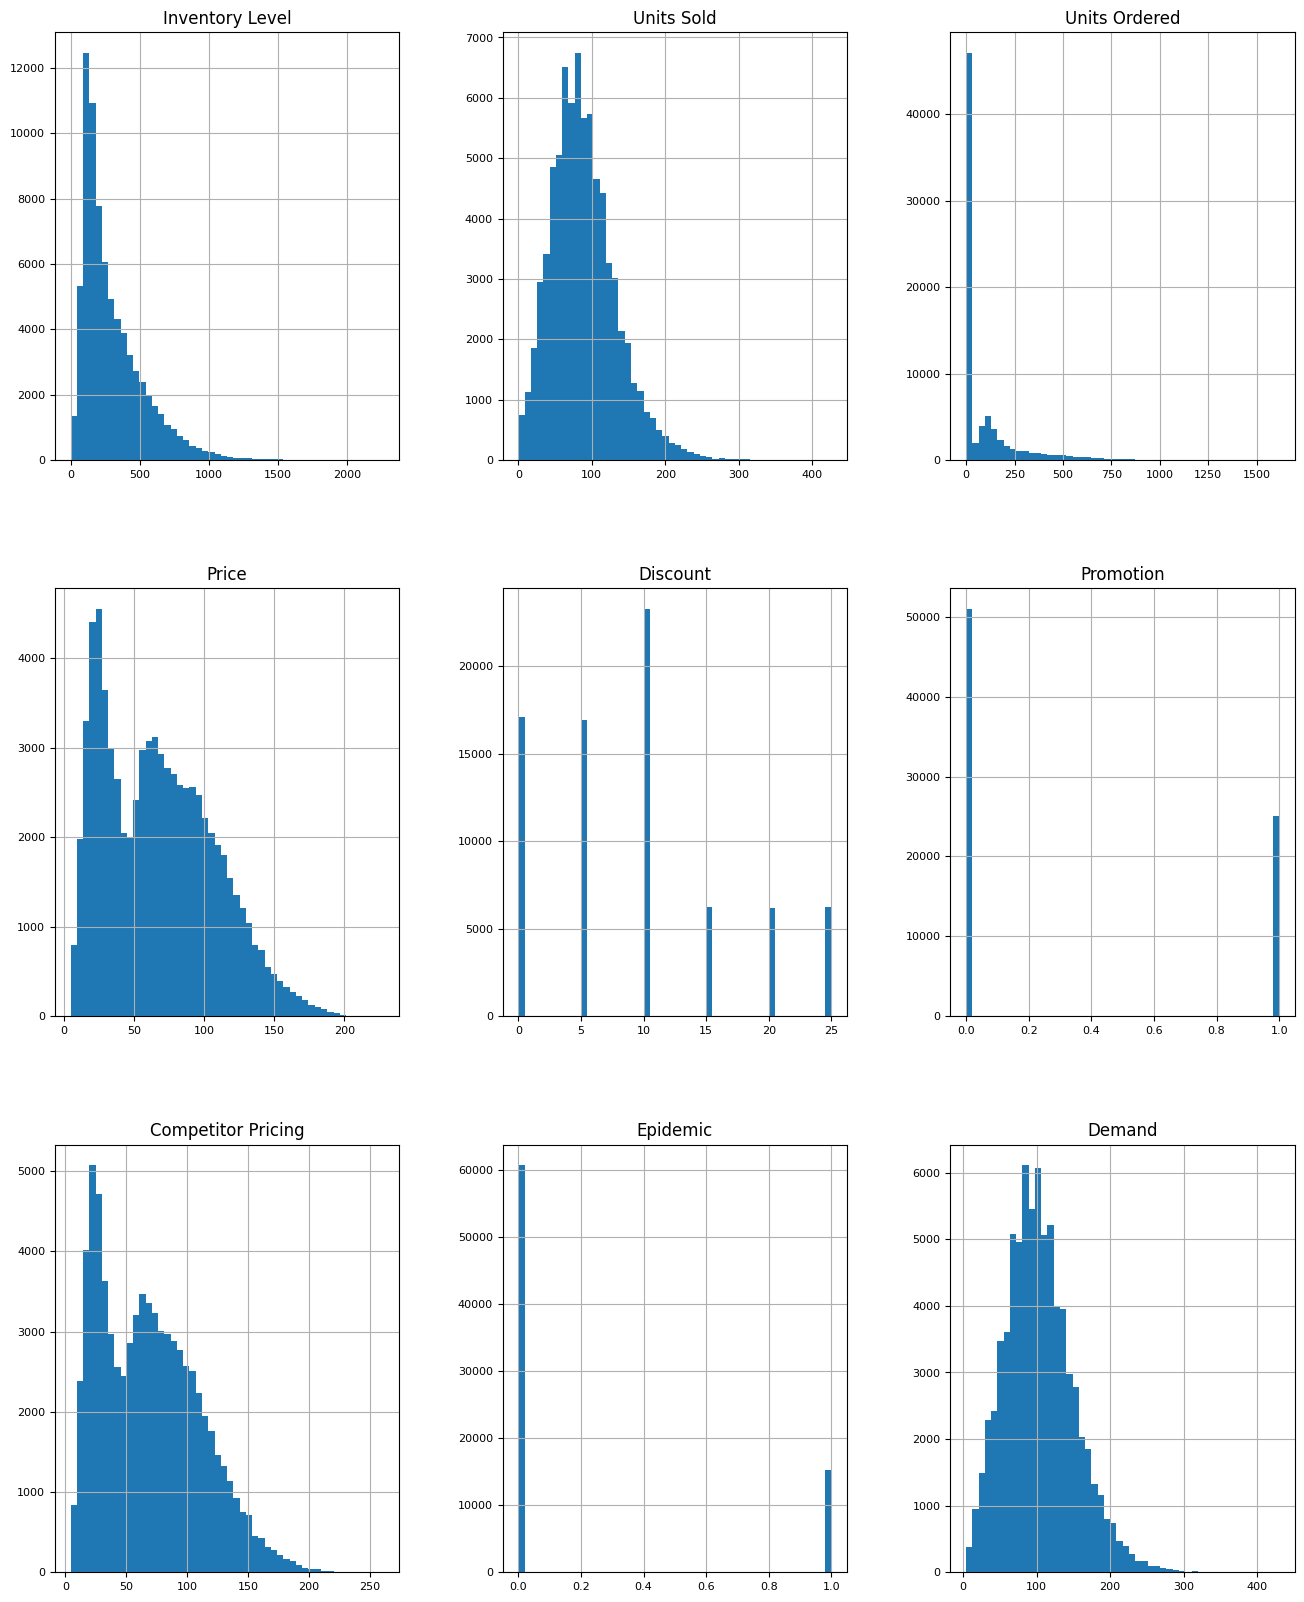

In [ ]:
df.hist(figsize=(16,20), bins=50, xlabelsize=8, ylabelsize=8)

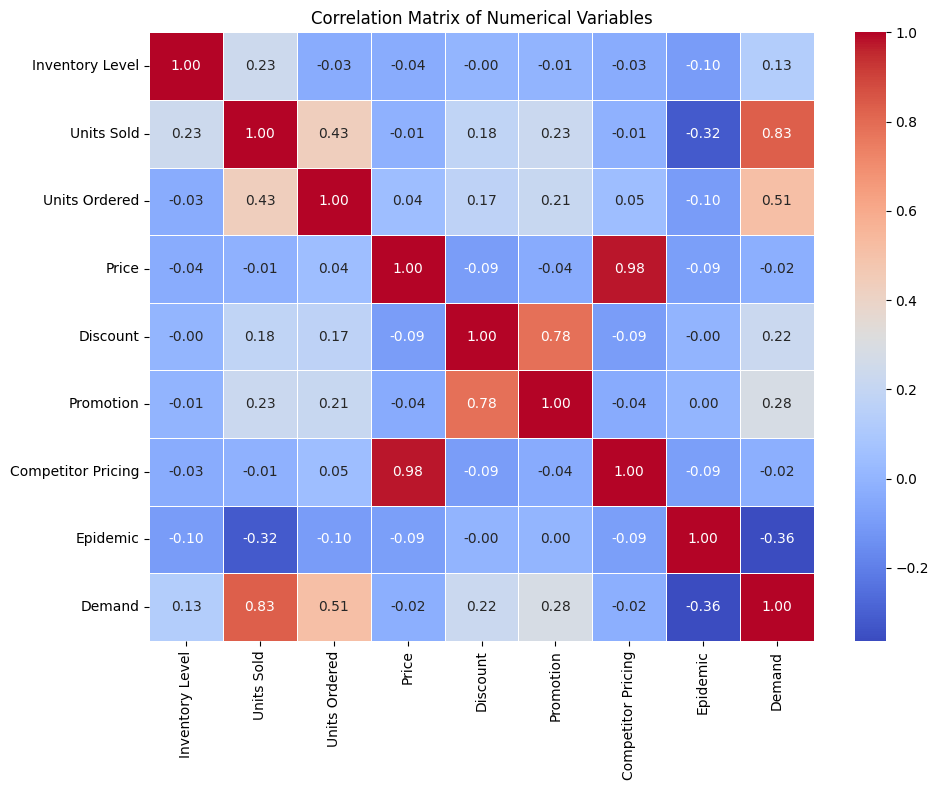

In [ ]:
# 2. Relationships: Correlation Heatmap of Numerical Features
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=[np.number]).columns
correlation_matrix = df[numeric_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()

/tmp/ipykernel_2913/3859451212.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Category', y='Demand', palette='Set2')


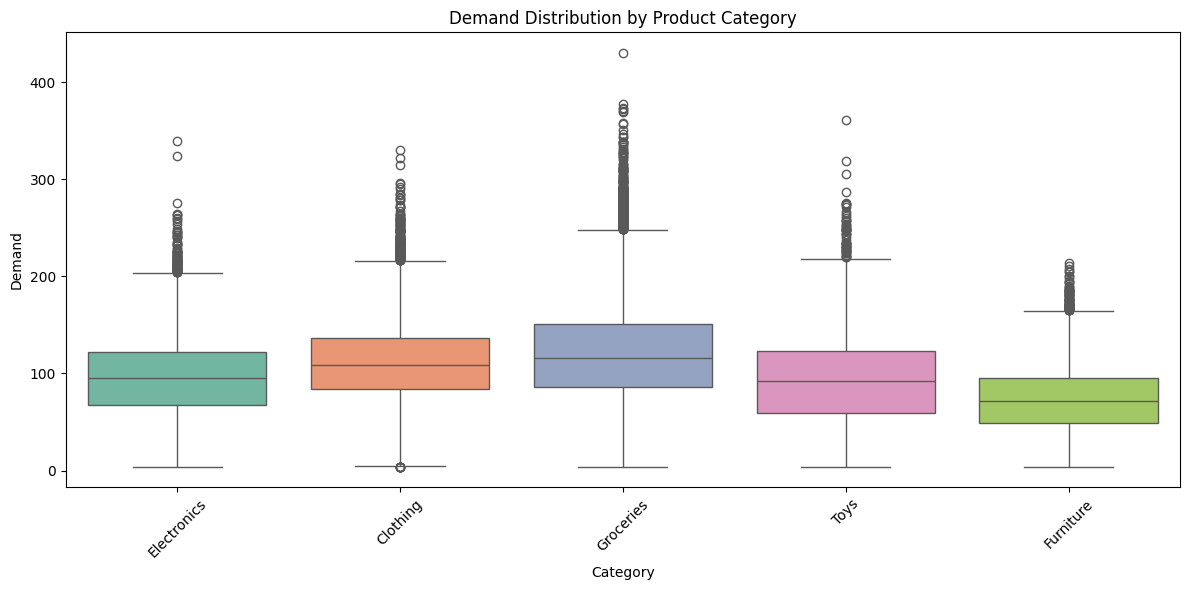

In [ ]:
# 3. Key Segment Analysis: Demand Distribution by Product Category
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Category', y='Demand', palette='Set2')
plt.title('Demand Distribution by Product Category')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
categorical_cols = ['Category', 'Region', 'Weather Condition',
                    'Seasonality']
for col in categorical_cols:
 print(df[col].unique())

['Electronics' 'Clothing' 'Groceries' 'Toys' 'Furniture']
['North' 'South' 'East' 'West']
['Snowy' 'Cloudy' 'Sunny' 'Rainy']
['Winter' 'Spring' 'Summer' 'Autumn']


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df[df['Date']=='2022-01-01']['Store ID'].unique()

array(['S001', 'S002', 'S003', 'S004', 'S005'], dtype=object)

In [ ]:
df['Date'].unique()

array(['2022-01-01', '2022-01-02', '2022-01-03', '2022-01-04',
       '2022-01-05', '2022-01-06', '2022-01-07', '2022-01-08',
       '2022-01-09', '2022-01-10', '2022-01-11', '2022-01-12',
       '2022-01-13', '2022-01-14', '2022-01-15', '2022-01-16',
       '2022-01-17', '2022-01-18', '2022-01-19', '2022-01-20',
       '2022-01-21', '2022-01-22', '2022-01-23', '2022-01-24',
       '2022-01-25', '2022-01-26', '2022-01-27', '2022-01-28',
       '2022-01-29', '2022-01-30', '2022-01-31', '2022-02-01',
       '2022-02-02', '2022-02-03', '2022-02-04', '2022-02-05',
       '2022-02-06', '2022-02-07', '2022-02-08', '2022-02-09',
       '2022-02-10', '2022-02-11', '2022-02-12', '2022-02-13',
       '2022-02-14', '2022-02-15', '2022-02-16', '2022-02-17',
       '2022-02-18', '2022-02-19', '2022-02-20', '2022-02-21',
       '2022-02-22', '2022-02-23', '2022-02-24', '2022-02-25',
       '2022-02-26', '2022-02-27', '2022-02-28', '2022-03-01',
       '2022-03-02', '2022-03-03', '2022-03-04', '2022-

In [ ]:
print(df.columns.tolist())
print(df.head())


['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality', 'Epidemic', 'Demand']
         Date Store ID Product ID     Category Region  Inventory Level  \
0  2022-01-01     S001      P0001  Electronics  North              195   
1  2022-01-01     S001      P0002     Clothing  North              117   
2  2022-01-01     S001      P0003     Clothing  North              247   
3  2022-01-01     S001      P0004  Electronics  North              139   
4  2022-01-01     S001      P0005    Groceries  North              152   

   Units Sold  Units Ordered  Price  Discount Weather Condition  Promotion  \
0         102            252  72.72         5             Snowy          0   
1         117            249  80.16        15             Snowy          1   
2         114            612  62.94        10             Snowy          1   
3          45         

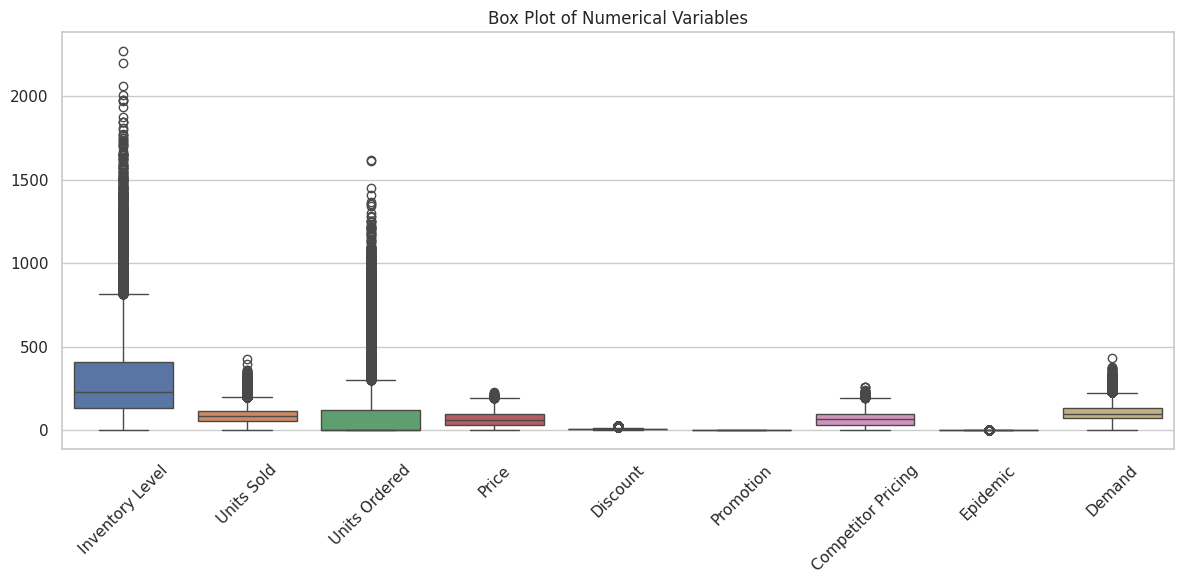

In [ ]:
#check for outliers
numerical_cols = []
for col in df.columns:
 if df[col].dtype in ['int64', 'float64']:
  numerical_cols.append(col)

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[numerical_cols])
plt.title('Box Plot of Numerical Variables')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
df['Store ID'].unique()
df['Product ID'].unique()
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                76000 non-null  object 
 1   Store ID            76000 non-null  object 
 2   Product ID          76000 non-null  object 
 3   Category            76000 non-null  object 
 4   Region              76000 non-null  object 
 5   Inventory Level     76000 non-null  int64  
 6   Units Sold          76000 non-null  int64  
 7   Units Ordered       76000 non-null  int64  
 8   Price               76000 non-null  float64
 9   Discount            76000 non-null  int64  
 10  Weather Condition   76000 non-null  object 
 11  Promotion           76000 non-null  int64  
 12  Competitor Pricing  76000 non-null  float64
 13  Seasonality         76000 non-null  object 
 14  Epidemic            76000 non-null  int64  
 15  Demand              76000 non-null  int64  
dtypes: f

In [5]:

# 1. Check duplicate Store-Product-Date combinations
duplicates = df.duplicated(
    subset=['Store ID', 'Product ID', 'Date'],
    keep=False
)

print("Duplicate rows:", duplicates.sum())
print(df.loc[duplicates].sort_values(
    ['Store ID', 'Product ID', 'Date']
).head(10))

# 2. Check missing dates within each Store-Product group
df['Date'] = pd.to_datetime(df['Date'])

missing_total = 0

for (store, product), group in df.groupby(
    ['Store ID', 'Product ID']
):
    dates = group['Date'].drop_duplicates().sort_values()

    expected = pd.date_range(
        dates.min(), dates.max(), freq='D'
    )

    missing = expected.difference(dates)
    missing_total += len(missing)

print("Total missing dates:", missing_total)


Duplicate rows: 0
Empty DataFrame
Columns: [Date, Store ID, Product ID, Category, Region, Inventory Level, Units Sold, Units Ordered, Price, Discount, Weather Condition, Promotion, Competitor Pricing, Seasonality, Epidemic, Demand]
Index: []
Total missing dates: 0


In [3]:

import pandas as pd

# 1. Copy data and convert Date
df_encoded = df.copy()
df_encoded['Date'] = pd.to_datetime(df_encoded['Date'])

# 2. Sort chronologically
df_encoded = df_encoded.sort_values(
    ['Store ID', 'Product ID', 'Date']
).reset_index(drop=True)

# 3. Calendar Features
df_encoded['Year'] = df_encoded['Date'].dt.year
df_encoded['Month'] = df_encoded['Date'].dt.month
df_encoded['Day'] = df_encoded['Date'].dt.day
df_encoded['DayOfWeek'] = df_encoded['Date'].dt.dayofweek
df_encoded['DayOfYear'] = df_encoded['Date'].dt.dayofyear
df_encoded['WeekOfYear'] = (
    df_encoded['Date'].dt.isocalendar().week.astype(int)
)
df_encoded['Is_Weekend'] = (
    df_encoded['DayOfWeek'].isin([5, 6]).astype(int)
)

# 4. Remove features that are not available
# at the time of forecasting
df_encoded = df_encoded.drop(
    columns=[
        'Units Sold',
        'Units Ordered',
        'Inventory Level',
        'Weather Condition',
        'Epidemic',
        'Competitor Pricing'
    ]
)
# 5. Keep Date for chronological splitting
# Do NOT drop Date yet


In [4]:
#splitting data
import pandas as pd
import numpy as np

from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# =====================================
# 1. Split chronologically by Date
# =====================================

dates = sorted(df_encoded['Date'].unique())

train_end = int(len(dates) * 0.70)
val_end = int(len(dates) * 0.85)

train_dates = dates[:train_end]
val_dates = dates[train_end:val_end]
test_dates = dates[val_end:]

train_df = df_encoded[df_encoded['Date'].isin(train_dates)].copy()
val_df = df_encoded[df_encoded['Date'].isin(val_dates)].copy()
test_df = df_encoded[df_encoded['Date'].isin(test_dates)].copy()

print("Train:", train_df['Date'].min(), "to", train_df['Date'].max())
print("Validation:", val_df['Date'].min(), "to", val_df['Date'].max())
print("Test:", test_df['Date'].min(), "to", test_df['Date'].max())

# =====================================
# 2. Prepare X and y
# =====================================

Train: 2022-01-01 00:00:00 to 2023-06-16 00:00:00
Validation: 2023-06-17 00:00:00 to 2023-10-08 00:00:00
Test: 2023-10-09 00:00:00 to 2024-01-30 00:00:00


In [5]:
# =====================================
# 2. Prepare X and y
# =====================================

target = 'Demand'
drop_cols = ['Demand', 'Date']

X_train = train_df.drop(columns=drop_cols)
y_train = train_df[target]

X_val = val_df.drop(columns=drop_cols)
y_val = val_df[target]

X_test = test_df.drop(columns=drop_cols)
y_test = test_df[target]


In [6]:
# =====================================
# 3. One-Hot Encoding
# =====================================

X_train = pd.get_dummies(X_train, dtype=int)
X_val = pd.get_dummies(X_val, dtype=int)
X_test = pd.get_dummies(X_test, dtype=int)

X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)


In [7]:
# =====================================
# 4. Train XGBoost with Validation
# =====================================

model = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=50
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=50,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=2000,
             n_jobs=-1, num_parallel_tree=None, ...)

In [8]:
# =====================================
# 5. Final evaluation on Test
# =====================================

test_pred = model.predict(X_test)

print("\n===== FINAL TEST RESULTS =====")
print("R2:", round(r2_score(y_test, test_pred), 4))
print("MAE:", round(mean_absolute_error(y_test, test_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, test_pred)), 4))
print("Best iteration:", model.best_iteration)


===== FINAL TEST RESULTS =====
R2: 0.9166
MAE: 9.9747
RMSE: 12.9691
Best iteration: 1999


                 Feature  Importance
37    Category_Furniture    0.125695
2              Promotion    0.092437
38    Category_Groceries    0.054327
39         Category_Toys    0.037979
36  Category_Electronics    0.036855
35     Category_Clothing    0.029621
20      Product ID_P0006    0.027913
27      Product ID_P0013    0.024303
28      Product ID_P0014    0.023233
47    Seasonality_Winter    0.021382


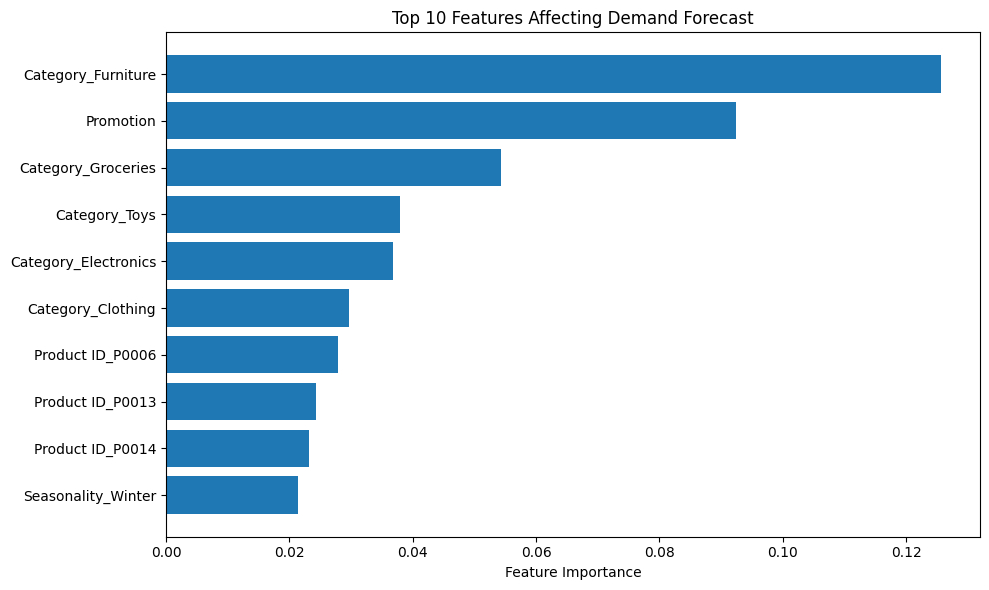

In [9]:

import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance', ascending=False
)

print(importance.head(10))

plt.figure(figsize=(10, 6))
top_features = importance.head(10).sort_values('Importance')
plt.barh(top_features['Feature'], top_features['Importance'])
plt.xlabel('Feature Importance')
plt.title('Top 10 Features Affecting Demand Forecast')
plt.tight_layout()
plt.show()


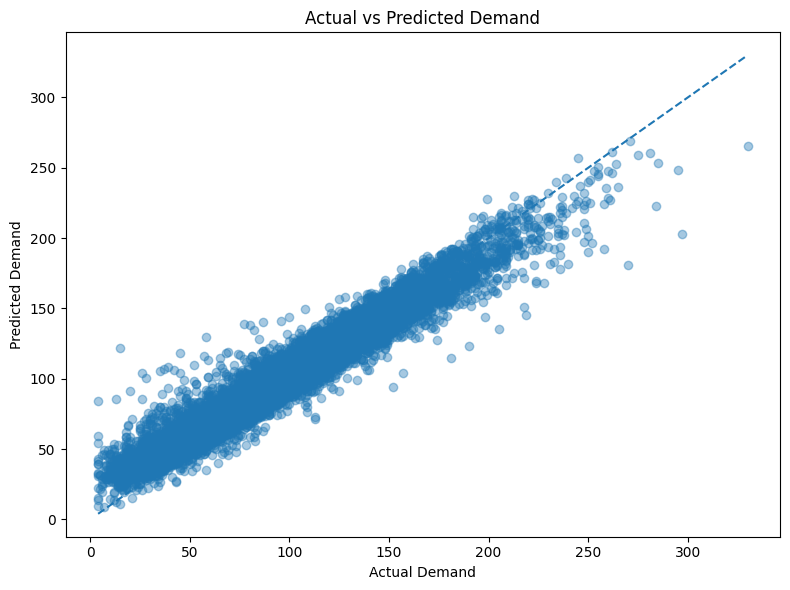

In [18]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, test_pred, alpha=0.4)

min_val = min(y_test.min(), test_pred.min())
max_val = max(y_test.max(), test_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], '--')

plt.xlabel('Actual Demand')
plt.ylabel('Predicted Demand')
plt.title('Actual vs Predicted Demand')
plt.tight_layout()
plt.show()


In [10]:

import joblib
from pathlib import Path

# Create a bundle containing the trained model and its metadata
bundle = {
    "model": model,
    "feature_columns": X_train.columns.tolist(),
    "metrics": {
        "R2": float(r2_score(y_test, test_pred)),
        "MAE": float(mean_absolute_error(y_test, test_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_test, test_pred))),
    },
    "category_options": {
    col: sorted(df_encoded[col].unique().tolist())
    for col in [
        "Store ID",
        "Product ID",
        "Category",
        "Region",
        "Seasonality",
    ]
}
    }

joblib.dump(bundle, "demand_model.joblib")
print("Model saved successfully!")


Model saved successfully!
